# Média móvel funciona?

**Python Finance Lab · Aula 9** · *Ibovespa x média móvel de 200 dias.*

**Pergunta atualizada:** acrescentar outubro ao backtest, no contexto do trade eleitoral, muda a comparação entre a regra de 200 pregões, o índice e o CDI?

**Dados coletados em 30/10/2026. Estudo comparável: 01/10/2021 a 29/10/2026**, com aquecimento desde 2020. O Yahoo já tem o fechamento de 30/10, mas o CDI SGS 12 ainda termina em 29/10. Usamos a última base completa comum, sem estimar a taxa ausente.[4][6]

**Como ler:** cada bloco explica o conceito, mostra o código e interpreta as saídas da execução real arquivada. O notebook normal consulta a internet; o reexecutor separado repete os snapshots sem rede. Biblioteca ou provedor podem revisar os dados numa execução futura.

## Parte 1 · A pergunta

### Bloco 1 · Abertura

A regra não recebe pesquisas eleitorais ou notícias. Ela usa sinal 1 quando o fechamento está acima da média dos últimos 200 pregões e sinal 0 nos demais casos; a posição usa o sinal anterior. O contexto editorial do trade eleitoral motiva ampliar o recorte, mas o teste não identifica o efeito causal da eleição.

A atualização acrescenta 20 pregões ao estudo. No trecho entre o fechamento de 30/09 e o de 29/10, a regra perdeu menos que o índice, mas também perdeu dinheiro na simulação. No período completo, continuou atrás do Ibovespa e do CDI. Uma regra pode perder menos num episódio e ainda ter desempenho agregado inferior.

Mantemos custo de 0,1% por mudança, a divisão retrospectiva entre escolha e teste e as mesmas fórmulas. Em Python, entram `rolling`, `shift` e `diff`.

*Conteúdo exclusivamente educacional. Não constitui recomendação de investimento.*


## Parte 2 · Conceitos

### Bloco 2 · O vocabulário da aula

**Média móvel.** Média dos últimos $n$ fechamentos, recalculada a cada observação. Duzentos pregões não são duzentos dias corridos.

**Sinal e posição.** O sinal é 1 acima da média e 0 nos demais casos. A posição usa o sinal anterior. No código, uma média indisponível também resulta em comparação falsa e sinal 0; o aquecimento anterior ao estudo evita depender dessa situação no intervalo avaliado.

**Backtest.** Simulação histórica sujeita a erros de dados, definição, seleção e execução. Um resultado passado não é uma previsão.

**Viés de olhar o futuro.** Usar uma informação que ainda não estava disponível para decidir a exposição do próprio intervalo. A comparação com o sinal contemporâneo é deliberadamente inválida, mesmo que em outra amostra ela não ganhe.

**Custos.** A dedução diária é 0,1% do patrimônio-base do intervalo quando a posição muda. É uma aproximação, não uma contabilidade completa de ordens, impostos e capital líquido de taxas.

**Excesso de ajuste.** Escolher uma regra após testar muitas alternativas pode ajustar sorte ou características específicas da amostra. Uma separação temporal ajuda a avaliar essa dependência, mas não torna um período já explorado prospectivamente intocado.

**Indicador chamado Sharpe.** Mantemos a fórmula didática do roteiro: diferença entre CAGRs dividida pela volatilidade do ativo. Ela não é o Sharpe clássico de retornos excedentes periódicos.[3]


## Parte 3 · Fórmulas

### Bloco 3 · As contas da aula

**Média móvel** de $n$ dias, no dia $t$:

$$MM_t = \frac{1}{n}\sum_{k=0}^{n-1} P_{t-k}$$

**Sinal** e **posição**:

$$s_t = \begin{cases} 1 & \text{se } P_t > MM_t \\ 0 & \text{caso contrário} \end{cases} \qquad\qquad p_t = s_{t-1}$$

**Retorno da estratégia** no dia $t$, com custo $c$ a cada troca de posição:

$$r^E_t = p_t\, r^{\text{Ibov}}_t + (1 - p_t)\, r^{\text{CDI}}_t - c\,\left|p_t - p_{t-1}\right|$$

O termo $|p_t - p_{t-1}|$ vale 1 nos dias de troca e 0 nos outros: o custo só é cobrado quando a posição muda.

*Exemplo à mão:* média móvel de 3 dias e preços 10, 11, 12, 9 e 8.

| Dia | Preço | Média de 3 dias | Sinal | Posição (sinal de ontem) |
|---|---|---|---|---|
| 1 | 10 | — | — | — |
| 2 | 11 | — | — | — |
| 3 | 12 | 11,0 | 1 | — |
| 4 | 9 | 10,7 | 0 | 1 |
| 5 | 8 | 9,7 | 0 | 0 |

No dia 4, o preço caiu de 12 para 9, mas a posição ainda era 1: a regra só "viu" a queda no fechamento do dia 4, e a carteira sofreu a queda inteira. Ela sai do Ibovespa no dia 5. Usar o sinal do próprio dia 4 teria evitado a queda, mas isso exige saber o fechamento antes de ele acontecer.

**Convenção de aquecimento.** Os travessões da tabela são didáticos e marcam a média ainda indisponível; não representam literalmente todos os valores do código. Para esses cinco preços, o código adota sinais 0,0,1,0,0 e posições NaN,0,0,1,0. O exemplo é hipotético, não uma série de pregões reais. A posição é idealizada no intervalo entre fechamentos, sem modelo de execução.


## Parte 4 · Implementação

### Bloco 4 · Importar as bibliotecas

As bibliotecas de sempre.


In [2]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import requests

**Leitura da saída real.**

Nenhuma saída é esperada das importações.


### Bloco 5 · As premissas

A regra precisa de 200 pregões de passado para calcular a primeira média. Por isso, os dados do Ibovespa começam em 2020, embora o teste comece em 01/10/2021, como nas outras aulas.

O período se divide como na aula 6: de outubro de 2021 a setembro de 2024 para escolher a janela, e de outubro de 2024 a 29 de outubro de 2026 para testá-la.

Os intervalos são inclusivos nas fatias do pandas e não se sobrepõem: escolha de 01/10/2021 a 30/09/2024; teste de 01/10/2024 a 29/10/2026. A referência básica continua sendo 200 pregões e o custo continua em 0,001; nenhum desses parâmetros foi retunado.

**Corte efetivo desta edição:** 29/10/2026. O alvo solicitado foi 30/10; o índice já tem esse fechamento, mas o CDI oficial ainda não tem a taxa de 30/10. Manter 30/10 sem o fator faltante trataria indevidamente a ausência como rendimento zero. O corte comum evita isso.


In [3]:
INDICE = "^BVSP"
DATA_DADOS = "2020-01-01"      # início do download: a média de 200 dias precisa de passado
DATA_INICIO = "2021-10-01"     # início do teste da regra
DATA_FIM = "2026-10-29"
FIM_ESCOLHA = "2024-09-30"     # último dia do período de escolha
INICIO_TESTE = "2024-10-01"    # primeiro dia do período de teste
JANELA = 200
CUSTO = 0.001                  # 0,1% do patrimônio a cada troca entre Ibovespa e CDI

**Leitura da saída real.**

Nenhuma saída é esperada das constantes. O limite solicitado foi 30/10/2026; o código usa 29/10/2026 como corte completo comum porque a SGS 12 ainda não publicou a taxa de 30/10. Não há taxa estimada ou cópia da véspera.


### Bloco 6 · Baixar e preparar os dados

Coletamos novamente os preços do Yahoo Finance e as taxas da série 12 do Banco Central.[4][5] O CDI vem em porcentagem diária; a função converte a taxa para fração. Acumulamos os fatores em todo o calendário bancário antes de alinhá-los aos pregões. O Yahoo preservado contém o fechamento de 30/10, mas a série de análise é limitada a 29/10 para combinar com a cobertura publicada do CDI.

A execução arquivada usa um adaptador privado de replay estrito sobre essas respostas reais, sem rede. O adaptador não integra as 14 células curriculares e não é uma resposta nova do provedor. Ao executar este notebook normalmente, as células fazem as consultas públicas.


In [4]:
dados_ibov = yf.download(
    INDICE, start=DATA_DADOS, auto_adjust=True, progress=False, multi_level_index=False
)
ibov = dados_ibov["Close"].loc[DATA_DADOS:DATA_FIM]


def baixar_sgs(serie, inicio, fim):
    """Baixa uma série do SGS do Banco Central e devolve uma Series com datas e números."""
    inicio_bc = pd.to_datetime(inicio).strftime("%d/%m/%Y")
    fim_bc = pd.to_datetime(fim).strftime("%d/%m/%Y")
    url = (
        f"https://api.bcb.gov.br/dados/serie/bcdata.sgs.{serie}/dados"
        f"?formato=json&dataInicial={inicio_bc}&dataFinal={fim_bc}"
    )
    resposta = requests.get(url, timeout=60)
    resposta.raise_for_status()
    tabela = pd.DataFrame(resposta.json())
    tabela["data"] = pd.to_datetime(tabela["data"], format="%d/%m/%Y")
    tabela["valor"] = tabela["valor"].astype(float)
    return tabela.set_index("data")["valor"]


cdi_diario = baixar_sgs(12, DATA_INICIO, DATA_FIM)
cota_cdi = (1 + cdi_diario / 100).cumprod()
print("Pregões do Ibovespa:", len(ibov), "| de", ibov.index[0].date(), "a", ibov.index[-1].date())

Pregões do Ibovespa: 1701 | de 2020-01-02 a 2026-10-29


**Leitura da saída real.**

A série usada tem **1701 fechamentos**, de **2020-01-02** a **2026-10-29**. Há **1267 pregões** no estudo e **1275 registros bancários** do CDI. O snapshot bruto/CSV do Yahoo também preserva 30/10; esse fechamento não entra nesta comparação porque falta o fator do CDI daquele dia. Os preços anteriores até setembro e as taxas históricas coincidem com a edição anterior.


### Bloco 7 · A média móvel

O `rolling(JANELA)` cria uma **janela móvel** de 200 linhas que anda pela série, e o `.mean()` calcula a média dentro de cada posição da janela. Nos primeiros 199 dias, ainda não há 200 preços, e o resultado fica vazio.

- `first_valid_index()` devolve a primeira data com valor, ou seja, o primeiro dia com média.
- A segunda conferência garante que, dentro do período de teste, nenhum dia ficou sem média. Foi para isso que baixamos os dados desde 2020.

O gráfico mostra o Ibovespa e a média no período de teste. Nos trechos em que a linha laranja está acima da cinza, o sinal é 1. A posição só incorpora esse sinal na observação seguinte.


Primeiro dia com média: 2020-10-19
Dias sem média no período de teste: 0


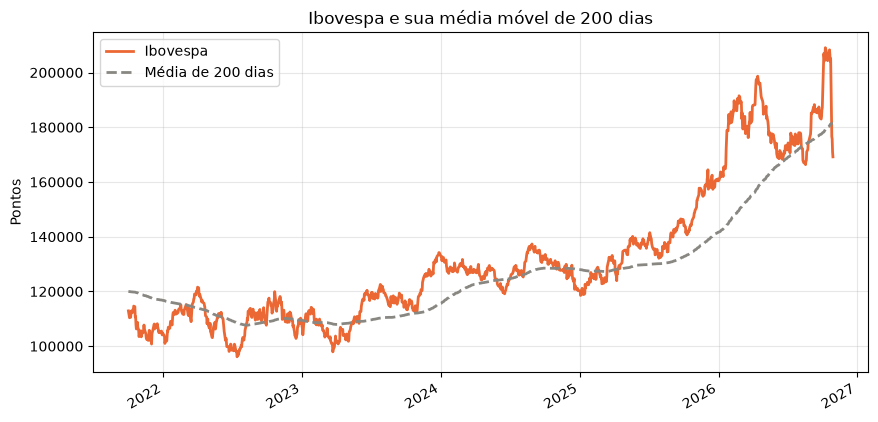

In [5]:
mm = ibov.rolling(JANELA).mean()
print("Primeiro dia com média:", mm.first_valid_index().date())
print("Dias sem média no período de teste:", mm.loc[DATA_INICIO:].isna().sum())

grafico = pd.DataFrame({"Ibovespa": ibov, f"Média de {JANELA} dias": mm}).loc[DATA_INICIO:]
ax = grafico.plot(
    figsize=(10, 5),
    style=["-", "--"],
    color=["#eb6834", "#898781"],
    linewidth=2,
    title=f"Ibovespa e sua média móvel de {JANELA} dias",
)
ax.set_ylabel("Pontos")
ax.set_xlabel("")
ax.grid(alpha=0.3)
plt.show()

**Leitura da saída real.**

Primeira média em **2020-10-19**; **0** médias ausentes no estudo. Foram **56** mudanças de sinal. Isso não autoriza aplicar o sinal ao retorno do mesmo dia.


### Bloco 8 · O sinal e a posição

Duas linhas de código fazem a regra inteira:

- `ibov > mm` compara o preço com a média em todos os dias de uma vez e devolve uma série de **verdadeiro ou falso**. O `.astype(int)` transforma verdadeiro em 1 e falso em 0: é o sinal.
- `sinal.shift(1)` **desloca** a série um dia para frente: o valor de ontem aparece na linha de hoje. É a posição, conforme a convenção do bloco 3. Isso evita o uso do sinal contemporâneo, mas não modela uma ordem de mercado.[2]

A tabela mostra os primeiros dias do período de teste, com as quatro colunas lado a lado, para conferir que a posição de cada dia é o sinal da linha anterior.


In [6]:
sinal = (ibov > mm).astype(int)
posicao = sinal.shift(1)

regra = pd.DataFrame({"Ibovespa": ibov, "Média": mm, "Sinal": sinal, "Posição": posicao})
regra.loc[DATA_INICIO:].head(8).round(0)

,Ibovespa,Média,Sinal,Posição
Date,,,,
2021-10-01,112900.0,119986.0,0,0.0
2021-10-04,110393.0,119963.0,0,0.0
2021-10-05,110458.0,119939.0,0,0.0
2021-10-06,110560.0,119917.0,0,0.0
2021-10-07,110585.0,119889.0,0,0.0
2021-10-08,112833.0,119863.0,0,0.0
2021-10-11,112180.0,119833.0,0,0.0
2021-10-13,113456.0,119812.0,0,0.0


**Leitura da saída real.**

A posição inicial é **CDI (0)**. Confira cada posição com o sinal da linha anterior. O histórico anterior ao estudo aquece a regra; a tabela exibida mostra as oito primeiras linhas, não outubro/2026.


### Bloco 9 · Os retornos e as trocas

Agora, a fórmula do retorno da estratégia, também para todos os dias de uma vez:

- `ret_ibov` é o retorno diário do Ibovespa.
- `ret_cdi` é o retorno diário do CDI nos dias de pregão. O `reindex(..., method="ffill")` leva a cota do CDI para o calendário do Ibovespa, como na aula 8, repetindo a última cota conhecida se faltar algum dia. Antes de outubro de 2021, não há CDI baixado; o `fillna(0)` evita buracos.
- `posicao.diff()` é a diferença entre a posição de hoje e a de ontem; o `.abs()` tira o sinal. O resultado vale 1 nos dias de troca e 0 nos outros: são as trocas.

O resto é a fórmula do bloco 3, linha por linha.

O CDI é acumulado no calendário bancário antes do alinhamento: os fatores dos dias sem bolsa não são descartados. O preenchimento do começo da série não é uma validação genérica de dados de mercado ausentes.


In [7]:
ret_ibov = ibov.pct_change()
ret_cdi = cota_cdi.reindex(ibov.index, method="ffill").pct_change().fillna(0)
trocas = posicao.diff().abs()

ret_estrategia = posicao * ret_ibov + (1 - posicao) * ret_cdi - CUSTO * trocas

no_periodo = trocas.loc[DATA_INICIO:DATA_FIM]
print("Trocas de posição no período:", int(no_periodo.sum()))
print(f"Tempo investido no Ibovespa: {posicao.loc[DATA_INICIO:DATA_FIM].mean():.0%}")

Trocas de posição no período: 56
Tempo investido no Ibovespa: 69%


**Leitura da saída real.**

Foram **56 trocas** e **68,59%** dos pregões no índice. O print arredonda a exposição para **69%**. O custo simplificado é 0,1% por mudança, não uma contabilidade de ordens e impostos.


### Bloco 10 · A função da estratégia

Vamos testar a regra com outras janelas, outros custos e outros períodos, então ela vira uma função. Ela repete os blocos 7 a 9 e devolve **dois valores**: a cota da estratégia no período, começando em 1, e o número de trocas. Na chamada, os dois valores são recebidos por dois nomes separados por vírgula, como os pares do `.items()` da aula 4.

O parâmetro `atraso`, com valor padrão 1, é o deslocamento do `shift`. Ele existe para a validação do bloco 16, que mostra o que acontece sem o atraso.

O teste confere que a função reproduz as contas feitas passo a passo.

**Base e continuidade.** Dividir pela primeira cota elimina o primeiro fator diário da série apresentada: o primeiro fechamento é a base, não um investimento anterior ao retorno daquele dia. A contagem de trocas segue o código original e pode incluir uma troca na primeira data de um recorte. No estudo completo, essa primeira data não teve troca em nenhuma das nove janelas. O teste posterior é um recorte de uma regra pré-aquecida, com estado histórico herdado, não uma implantação nova de carteira.


In [8]:
def estrategia_media_movel(ibov, ret_cdi, janela, custo, inicio, fim, atraso=1):
    """Cota da regra: no Ibovespa acima da média móvel, no CDI abaixo dela."""
    mm = ibov.rolling(janela).mean()
    sinal = (ibov > mm).astype(int)
    posicao = sinal.shift(atraso)
    trocas = posicao.diff().abs()
    ret = posicao * ibov.pct_change() + (1 - posicao) * ret_cdi - custo * trocas
    cota = (1 + ret.loc[inicio:fim]).cumprod()
    return cota / cota.iloc[0], trocas.loc[inicio:fim].sum()


cota_mm, n_trocas = estrategia_media_movel(ibov, ret_cdi, JANELA, CUSTO, DATA_INICIO, DATA_FIM)
cota_passo_a_passo = (1 + ret_estrategia.loc[DATA_INICIO:DATA_FIM]).cumprod()
cota_passo_a_passo = cota_passo_a_passo / cota_passo_a_passo.iloc[0]
print("Diferença para o passo a passo:", round((cota_mm - cota_passo_a_passo).abs().max(), 10))
print("Trocas:", int(n_trocas))

Diferença para o passo a passo: 0.0
Trocas: 56


**Leitura da saída real.**

Diferença máxima em relação ao passo a passo: **0.0** na precisão exibida. Ambas contam **56 trocas**. A primeira cota é 1 pelo primeiro fechamento-base; não representa uma compra anterior ao primeiro retorno.


### Bloco 11 · A estratégia × ficar sempre investido

A comparação mantém as três cotas começando em 1 no primeiro fechamento do estudo. A estratégia é roxa, o índice é laranja e o CDI é verde.

**Mesmo calendário.** O CDI já foi acumulado sobre todos os seus dias bancários. Agora sua cota é levada ao mesmo índice de datas da cota do Ibovespa e só então normalizada. Assim, `curvas` não introduz datas bancárias vazias nas colunas de bolsa, e os retornos subsequentes usam observações comparáveis.[1]

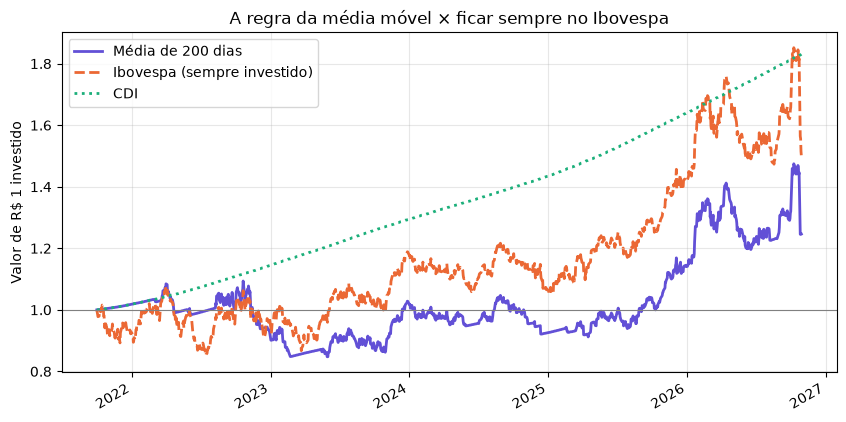

In [9]:
cota_ibov = ibov.loc[DATA_INICIO:DATA_FIM] / ibov.loc[DATA_INICIO:DATA_FIM].iloc[0]
cota_cdi_periodo = cota_cdi.reindex(cota_ibov.index, method="ffill")
cota_cdi_periodo = cota_cdi_periodo / cota_cdi_periodo.iloc[0]

curvas = pd.DataFrame({
    f"Média de {JANELA} dias": cota_mm,
    "Ibovespa (sempre investido)": cota_ibov,
    "CDI": cota_cdi_periodo,
})

ax = curvas.plot(
    figsize=(10, 5),
    style=["-", "--", ":"],
    color=["#6250d6", "#eb6834", "#1baf7a"],
    linewidth=2,
    title="A regra da média móvel × ficar sempre no Ibovespa",
)
ax.axhline(1, color="gray", linewidth=0.8)
ax.set_ylabel("Valor de R$ 1 investido")
ax.set_xlabel("")
ax.grid(alpha=0.3)
plt.show()

**Leitura da saída real.**

O CDI terminou na frente, seguido pelo índice e pela regra padrão. As três curvas têm **1267 datas e 1266 retornos válidos por coluna**, sem vazios. Todos os fatores bancários foram acumulados antes do alinhamento aos pregões. Isso conserva juros entre avaliações, sem confundir os calendários.


### Bloco 12 · As medidas da aula 2

Aplicamos crescimento anual composto (CAGR), volatilidade amostral anualizada com 252 períodos e queda máxima desde um pico às mesmas datas de avaliação.

A coluna chamada **Sharpe** mantém exatamente a fórmula do roteiro: CAGR do ativo menos CAGR do CDI, dividido pela volatilidade do ativo. Não foi trocada pelo Sharpe clássico de excessos periódicos e não deve ser descrita automaticamente como a comparação “mais justa”.[3]

Depois de alinhar as cotas, as três alternativas têm 1267 observações e 1266 retornos válidos. A redução da volatilidade não garante redução da queda máxima. O CDI é uma referência idealizada; sua pequena volatilidade nesta amostra depende das taxas e dos intervalos entre pregões.


In [10]:
def retorno_anual(serie):
    """Retorno médio por ano, com juros compostos (anos contados em dias corridos)."""
    anos = (serie.index[-1] - serie.index[0]).days / 365.25
    return (serie.iloc[-1] / serie.iloc[0]) ** (1 / anos) - 1


def volatilidade_anual(serie, periodos_por_ano=252):
    """Desvio padrão dos retornos, levado para a escala de um ano."""
    return serie.pct_change().dropna().std() * periodos_por_ano ** 0.5


def queda_maxima(serie):
    """A pior queda do período, do pico ao fundo."""
    return (serie / serie.cummax() - 1).min()


def sharpe(serie, cdi, periodos_por_ano=252):
    """Retorno acima do CDI por ano, para cada ponto de volatilidade."""
    return (retorno_anual(serie) - retorno_anual(cdi)) / volatilidade_anual(serie, periodos_por_ano)


medidas = pd.DataFrame(index=curvas.columns)
for nome in curvas.columns:
    medidas.loc[nome, "Retorno ao ano (%)"] = retorno_anual(curvas[nome]) * 100
    medidas.loc[nome, "Volatilidade ao ano (%)"] = volatilidade_anual(curvas[nome]) * 100
    medidas.loc[nome, "Queda máxima (%)"] = queda_maxima(curvas[nome]) * 100
    medidas.loc[nome, "Sharpe"] = sharpe(curvas[nome], cota_cdi_periodo)

print("Trocas da estratégia:", int(n_trocas))
medidas.round(2)

Trocas da estratégia: 56


,Retorno ao ano (%),Volatilidade ao ano (%),Queda máxima (%),Sharpe
Média de 200 dias,4.43,15.24,-22.51,-0.54
Ibovespa (sempre investido),8.29,18.80,-20.93,-0.23
CDI,12.65,0.12,0.00,0.00


**Leitura da saída real.**

| Alternativa | Retorno ao ano (%) | Volatilidade ao ano (%) | Queda máxima (%) | Sharpe |
| --- | --- | --- | --- | --- |
| Média de 200 dias | 4,43 | 15,24 | -22,51 | -0,54 |
| Ibovespa (sempre investido) | 8,29 | 18,80 | -20,93 | -0,23 |
| CDI | 12,65 | 0,12 | 0,00 | 0,00 |

A menor volatilidade da estratégia não impediu a maior queda máxima. O zero do CDI no indicador decorre de ser a própria referência do numerador; a coluna mantém a razão didática CAGR-excesso/volatilidade, não o Sharpe clássico.[3]


### Bloco 13 · O peso do custo

Quanto o custo de negociação pesa no resultado? Rodamos a mesma regra com três custos por troca: zero, 0,1% e 0,5%. Como a função recebe o custo como parâmetro, basta um laço.


In [11]:
efeito_custo = pd.DataFrame()
for custo in [0, 0.001, 0.005]:
    cota, _ = estrategia_media_movel(ibov, ret_cdi, JANELA, custo, DATA_INICIO, DATA_FIM)
    efeito_custo.loc[f"{custo:.1%} por troca", "Retorno ao ano (%)"] = retorno_anual(cota) * 100
    efeito_custo.loc[f"{custo:.1%} por troca", "Sharpe"] = sharpe(cota, cota_cdi_periodo)

efeito_custo.round(2)

,Retorno ao ano (%),Sharpe
0.0% por troca,5.59,-0.46
0.1% por troca,4.43,-0.54
0.5% por troca,-0.08,-0.83


**Leitura da saída real.**

| Custo | Retorno ao ano (%) | Sharpe |
| --- | --- | --- |
| 0.0% por troca | 5,59 | -0,46 |
| 0.1% por troca | 4,43 | -0,54 |
| 0.5% por troca | -0,08 | -0,83 |

De custo zero para 0,5% por troca, o crescimento anual caiu **5,67 pontos percentuais**, calculados com valores não arredondados. Com o custo maior, o CAGR ficou ligeiramente negativo. Essa diferença não é a simples soma das taxas: o patrimônio também compõe sobre bases alteradas.


### Bloco 14 · Testando muitas janelas

Por que 200 dias? A janela é uma escolha. Vamos testar de 50 a 250 dias, de 25 em 25, no período inteiro, e ver qual teria sido a melhor.

`range(50, 251, 25)` gera 50, 75, 100... até 250: o terceiro número é o passo.

A vencedora significa apenas a de maior indicador entre essas nove candidatas, com essa fórmula e nesse intervalo. A busca no período inteiro é deliberadamente retrospectiva e não define uma decisão que alguém teria tomado em 2021.


In [12]:
por_janela = pd.DataFrame()
for janela in range(50, 251, 25):
    cota, n = estrategia_media_movel(ibov, ret_cdi, janela, CUSTO, DATA_INICIO, DATA_FIM)
    por_janela.loc[janela, "Retorno ao ano (%)"] = retorno_anual(cota) * 100
    por_janela.loc[janela, "Sharpe"] = sharpe(cota, cota_cdi_periodo)
    por_janela.loc[janela, "Trocas"] = n

por_janela.index.name = "Janela (dias)"
print("Melhor janela no período inteiro:", por_janela["Sharpe"].idxmax(), "dias")
por_janela.round(2)

Melhor janela no período inteiro: 75 dias


,Retorno ao ano (%),Sharpe,Trocas
Janela (dias),,,
50,6.04,-0.46,106.0
75,10.17,-0.17,68.0
100,8.88,-0.26,56.0
125,5.19,-0.50,62.0
150,3.29,-0.61,62.0
175,0.76,-0.79,80.0
200,4.43,-0.54,56.0
225,5.85,-0.44,46.0
250,6.76,-0.39,46.0


**Leitura da saída real.**

| Janela (pregões) | Retorno ao ano (%) | Sharpe | Trocas |
| --- | --- | --- | --- |
| 50 | 6,04 | -0,46 | 106,00 |
| 75 | 10,17 | -0,17 | 68,00 |
| 100 | 8,88 | -0,26 | 56,00 |
| 125 | 5,19 | -0,50 | 62,00 |
| 150 | 3,29 | -0,61 | 62,00 |
| 175 | 0,76 | -0,79 | 80,00 |
| 200 | 4,43 | -0,54 | 56,00 |
| 225 | 5,85 | -0,44 | 46,00 |
| 250 | 6,76 | -0,39 | 46,00 |

Melhor candidata, pelo indicador didático, entre as nove no período inteiro: **75 pregões**. CAGR **10,17%**, contra **4,43%** da janela 200. É seleção retrospectiva; a candidata vencedora não superou o CDI no período completo.


### Bloco 15 · Escolher num período, testar no outro

A escolha usa apenas 01/10/2021 a 30/09/2024 para comparar as nove janelas. Em seguida, avaliamos a selecionada de 01/10/2024 a 29/10/2026, junto da janela padrão 200, do Ibovespa e do CDI.

O histórico anterior continua disponível para aquecer as médias: isso é causal. A cota é recortada e renormalizada, herdando o estado da regra; não representa necessariamente uma carteira migrando naquele dia para a janela selecionada.

O índice zero após a chamada pega somente a cota, primeiro elemento do par devolvido. A separação é retrospectiva: B14 já explorou a amostra inteira, portanto não certifica teste prospectivo intocado. Não reajustamos a grade após ver o resultado posterior.


In [13]:
sharpe_escolha = pd.Series(dtype=float)
cdi_escolha = cota_cdi.loc[DATA_INICIO:FIM_ESCOLHA]
for janela in range(50, 251, 25):
    cota, _ = estrategia_media_movel(ibov, ret_cdi, janela, CUSTO, DATA_INICIO, FIM_ESCOLHA)
    sharpe_escolha.loc[janela] = sharpe(cota, cdi_escolha)

janela_escolhida = sharpe_escolha.idxmax()
print("Janela escolhida no período de escolha:", janela_escolhida, "dias")

cdi_teste = cota_cdi.loc[INICIO_TESTE:DATA_FIM]
ibov_teste = ibov.loc[INICIO_TESTE:DATA_FIM]
teste = {
    f"Média de {janela_escolhida} dias (escolhida)": estrategia_media_movel(
        ibov, ret_cdi, janela_escolhida, CUSTO, INICIO_TESTE, DATA_FIM)[0],
    f"Média de {JANELA} dias (padrão)": estrategia_media_movel(
        ibov, ret_cdi, JANELA, CUSTO, INICIO_TESTE, DATA_FIM)[0],
    "Ibovespa (sempre investido)": ibov_teste / ibov_teste.iloc[0],
    "CDI": cdi_teste / cdi_teste.iloc[0],
}

resultado_teste = pd.DataFrame(index=list(teste))
for nome, cota in teste.items():
    resultado_teste.loc[nome, "Retorno ao ano (%)"] = retorno_anual(cota) * 100
    resultado_teste.loc[nome, "Sharpe"] = sharpe(cota, cdi_teste)

resultado_teste.round(2)

Janela escolhida no período de escolha: 75 dias


,Retorno ao ano (%),Sharpe
Média de 75 dias (escolhida),10.72,-0.18
Média de 200 dias (padrão),10.66,-0.18
Ibovespa (sempre investido),12.50,-0.07
CDI,13.89,0.00


**Leitura da saída real.**

Janela escolhida no primeiro intervalo: **75 pregões**, sem mudança após acrescentar outubro. Escolha: 01/10/2021–30/09/2024; teste: 01/10/2024–29/10/2026. Os nove escores de escolha são idênticos aos da edição anterior.

| Alternativa | Retorno ao ano (%) | Sharpe |
| --- | --- | --- |
| Média de 75 dias (escolhida) | 10,72 | -0,18 |
| Média de 200 dias (padrão) | 10,66 | -0,18 |
| Ibovespa (sempre investido) | 12,50 | -0,07 |
| CDI | 13,89 | 0,00 |

A escolhida teve CAGR ligeiramente maior que a padrão, mas ambas ficaram abaixo do índice e do CDI. Não confunda essa comparação de CAGR com a ordenação do indicador Sharpe didático: seus denominadores também diferem. O estudo continua retrospectivo, com estado da regra herdado.


## Parte 5 · Validação

### Bloco 16 · A prova do viés de olhar o futuro

Chamamos a mesma função com atraso 1 e atraso 0. Na variante 0, o fechamento atual decide a exposição aplicada ao retorno do próprio dia: essa comparação usa informação futura em relação ao começo do intervalo.

O teste é inválido independentemente de ganhar ou perder. Nesta amostra a variante enviesada ganhou com folga, mas isso não é uma propriedade garantida de qualquer série. A variante deslocada também mantém uma execução idealizada, sem modelar abertura, latência ou ordens.


In [14]:
honesta, _ = estrategia_media_movel(ibov, ret_cdi, JANELA, CUSTO, DATA_INICIO, DATA_FIM, atraso=1)
vidente, _ = estrategia_media_movel(ibov, ret_cdi, JANELA, CUSTO, DATA_INICIO, DATA_FIM, atraso=0)

print(f"Com atraso de um dia (honesta): {retorno_anual(honesta) * 100:.2f}% ao ano")
print(f"Sem atraso (olhando o futuro):  {retorno_anual(vidente) * 100:.2f}% ao ano")

Com atraso de um dia (honesta): 4.43% ao ano
Sem atraso (olhando o futuro):  27.47% ao ano


**Leitura da saída real.**

**Atraso 1: 4,43% ao ano. Sem atraso: 27,47% ao ano.** A variante sem atraso usa informação inadequada para decidir a exposição do mesmo intervalo. Seu número não prova execução ou previsão; esse erro existiria mesmo numa amostra em que ela não ganhasse.


### Bloco 17 · Conferência manual do sinal

Por fim, conferimos a média móvel e o sinal à mão em três datas do período: o primeiro pregão, um do meio e o último.

- `ibov.loc[:data].tail(JANELA)` pega os 200 últimos fechamentos até a data, inclusive; a média deles tem de ser igual à média móvel calculada pelo `rolling`.
- O sinal da data tem de ser 1 se o fechamento estiver acima da média, e 0 se não estiver.

A igualdade arredondada que aparece na tela não substitui validação preventiva de dados. Intervalos vazios, preços inválidos e faltas no provedor exigem validação antes de usar o código com outros dados ou períodos.


In [15]:
periodo = ibov.loc[DATA_INICIO:DATA_FIM].index
for data in [periodo[0], periodo[len(periodo) // 2], periodo[-1]]:
    media_manual = ibov.loc[:data].tail(JANELA).mean()
    if ibov.loc[data] > media_manual:
        sinal_manual = 1
    else:
        sinal_manual = 0
    print(
        data.date(),
        f"| média: {media_manual:.0f} (rolling: {mm.loc[data]:.0f})",
        f"| sinal: {sinal_manual} (calculado: {sinal.loc[data]})",
    )

2021-10-01 | média: 119986 (rolling: 119986) | sinal: 0 (calculado: 0)
2024-04-18 | média: 123125 (rolling: 123125) | sinal: 1 (calculado: 1)
2026-10-29 | média: 181432 (rolling: 181432) | sinal: 0 (calculado: 0)


**Leitura da saída real.**

- 2021-10-01: média manual 119986, rolling 119986; sinal manual 0, calculado 0.
- 2024-04-18: média manual 123125, rolling 123125; sinal manual 1, calculado 1.
- 2026-10-29: média manual 181432, rolling 181432; sinal manual 0, calculado 0.

A data central mudou porque o estudo ganhou 20 pregões. Conferir três exemplos não substitui validar toda a série, calendários e fontes.


## Parte 6 · Interpretação

### Bloco 18 · O que os números atualizados dizem

De **01/10/2021 a 29/10/2026**, a regra de 200 pregões fez **56 trocas** e ficou **68,59%** dos pregões no Ibovespa. Seu CAGR foi **4,43% ao ano**, contra **8,29%** do índice e **12,65%** do CDI.

A volatilidade anual da regra foi **15,24%**, contra **18,80%** do índice, mas a pior queda continuou em **-22,51%**, pior que **-20,93%**. São medidas diferentes. Sem custo por troca, a regra ainda não superou o índice; com custo de 0,5%, seu CAGR ficou em **-0,08%**.

**O que outubro acrescentou.** Do fechamento de 30/09 ao de 29/10, a regra retornou **-5,17%**, o índice **-9,21%**, e o CDI **1,02%**. Esses são retornos acumulados do trecho, não taxas anualizadas. A base em 30/09 inclui o primeiro retorno de outubro.

Em **26/10**, o índice fechou em **176.608 pontos**, abaixo da média de **181.299,82**. O sinal passou a 0, mas a posição daquele intervalo ainda era 1. A regra sofreu a queda do dia 26; a posição passou ao CDI apenas em **27/10**. Não houve antecipação da queda com o sinal do próprio dia. Os registros de preço e posição descrevem o que a simulação fez, não provam a causa política do movimento.

A janela de **75 pregões** permaneceu escolhida no primeiro intervalo. No teste posterior, seu CAGR foi **10,72%**, contra **10,66%** da padrão, **12,50%** do índice e **13,89%** do CDI. O CDI ficou na frente nesse recorte também. Não escolhemos uma nova janela depois de ver outubro.

**O que mudou em relação à edição até setembro.** O CAGR da regra passou de **5,62%** para **4,43%**; o do índice, de **10,55%** para **8,29%**. Os históricos anteriores coincidem, mas os novos retornos e o tempo de anualização mudaram os resultados. Não foi apenas uma troca de legenda.

Isso não prova que toda média móvel falha. O resultado responde a estas regras, dados e convenções; regime, sobreajuste e variabilidade não foram isolados causalmente.


## Parte 7 · Limitações

### Bloco 19 · O que esta análise não mostra

- **Um índice e um período.** Pouco mais de cinco anos de uma referência não estabelecem desempenho em outros mercados ou crises.
- **Exposição idealizada.** O sinal anterior é aplicado ao retorno entre fechamentos. Isso não representa negociar apenas no fechamento seguinte nem comprova que o preço usado seria executável após conhecer o sinal. Não simulamos abertura, latência ou livro de ordens.
- **Custos simplificados.** A dedução é sobre a base do intervalo. Não modela impostos, spread, implantação/liquidação completa ou capital já reduzido por todos os encargos.
- **Primeiro fechamento como base.** A normalização remove o primeiro fator diário apresentado; a contagem de trocas pode incluir a data inicial. Esse tratamento foi preservado, não convertido para um investimento antes do primeiro retorno.
- **Referências, não produtos.** Ibovespa e CDI não são aplicações diretamente negociáveis nas condições ideais do código; fundos e outros veículos têm características próprias.
- **Definição do indicador.** A coluna Sharpe é a razão CAGR-excesso/volatilidade mantida do roteiro, não o Sharpe clássico.[3]
- **Seleção retrospectiva.** O período inteiro foi explorado antes da divisão didática, e o estado histórico da regra é herdado. Não é uma comprovação prospectiva.
- **Dados e robustez.** O código não trata falhas de conexão nem intervalos vazios e não confere o calendário oficial da B3. Falhas ou revisões das fontes exigem conferência antes de calcular.
- **Sem garantia.** Frequência de trocas e resultado de alguns episódios não demonstram habilidade nem eliminam a possibilidade de perdas.

**Disponibilidade desigual das fontes.** Nesta coleta, o índice tem 30/10, mas a SGS 12 não. A comparação para em 29/10; o fechamento adicional foi preservado nos dados, não misturado com um CDI estimado. O pipeline privado validou a base antes da execução; isso não adiciona tratamento de erros ao código curricular simples.


## Parte 8 · Exercícios

### Bloco 20 · Para praticar

1. **Na carteira.** Baixe as ações desde 2020, normalize cada série pelo primeiro preço e tire a média por linha para uma carteira inicial com pesos iguais. Mantenha passado para aquecer as médias e declare a convenção de manutenção da carteira.
2. **Duas médias.** Compare a de 50 com a de 200 pregões. Só use o sinal com a defasagem declarada e compare as mudanças de posição.
3. **Custos maiores.** Teste 1% por troca sem mudar os dados. Compare o impacto no crescimento, sabendo que o modelo continua simplificado.
4. **Bitcoin em reais.** Use observações diárias, inclusive fins de semana. 200 observações cobrem um intervalo diferente de 200 pregões da bolsa. Reveja o calendário do CDI e a anualização da volatilidade; não reutilize 252 períodos sem adequar a convenção. Garanta aquecimento antes do estudo.
5. **Outra divisão sem sobreposição.** Por exemplo, escolha de 01/10/2021 a 30/09/2023 e teste de 01/10/2023 a 29/10/2026. Essas são novas propostas de exercício, não resultados executados nesta aula. Não escolha depois somente a divisão favorável.


## Resumo

### Bloco 21 · O que aprendemos

**Em finanças:** média móvel resume preços já vistos; defasar o sinal evita esse uso de informação contemporânea, mas não comprova execução real. Custos, calendário, base de normalização e definição de métricas precisam ser explícitos. Uma escolha retrospectiva deve ser qualificada e nenhum desses cuidados garante desempenho futuro.

**Em Python:** `rolling(n).mean()` calcula a média; comparações entre séries e `astype(int)` geram o sinal; `shift(1)` leva o sinal anterior para a linha atual; `diff().abs()` identifica mudanças. Uma função pode devolver dois valores; o sublinhado recebe um valor não utilizado; `range` aceita passo e duas barras fazem divisão inteira.

**Conclusão desta amostra:** a regra padrão perdeu em crescimento e em queda máxima, embora sua volatilidade tenha sido menor. No recorte de outubro, perdeu menos que o índice, mas isso não reverteu o resultado do período completo. As três curvas e seus retornos compartilham o mesmo calendário de avaliação.


## Gancho para a aula 10

### Bloco 22 · Próxima aula

Em nove aulas, medimos o passado de todos os jeitos: retorno, risco, aportes, rebalanceamento, diversificação, otimização, cripto e uma regra de entrada e saída. Falta a pergunta que todo mundo quer fazer: e o futuro?

Ninguém sabe o futuro, mas dá para estudar a gama de futuros possíveis. Na última aula da temporada, vamos simular 10 mil caminhos para quem aporta R\$ 200 por mês durante 10 anos, construir os cenários pessimista, mediano e otimista e entregar um simulador interativo. E vamos guardar todas as funções da série num arquivo próprio, para chamá-las com uma linha.

Os cenários da próxima aula serão condicionais às hipóteses da simulação, não previsões nem probabilidades garantidas do mundo real.


## Glossário da aula

| Termo | Significado |
|---|---|
| Média móvel | Média dos últimos $n$ preços, recalculada a cada dia |
| Sinal | Indicação da regra: 1 para o índice, 0 para o CDI; não é a posição do mesmo intervalo |
| Posição | Exposição idealizada em cada intervalo; sinal da observação anterior nesta convenção |
| Backtest | Simulação de uma regra de investimento com dados do passado |
| Viés de olhar o futuro | Erro de usar no backtest uma informação que ainda não existia |
| Custo de transação | Dedução diária aproximada por mudança de posição, não uma contabilidade de ordens |
| Excesso de ajuste | Selecionar uma regra ajustada a particularidades do histórico que podem não se repetir |
| `rolling` | Cria uma janela móvel para calcular médias e outras medidas |
| `shift` | Desloca uma série no tempo |
| `diff` | Diferença entre um valor e o anterior |


## Sources

[1] https://pandas.pydata.org/docs/reference/api/pandas.Series.pct_change.html
[2] https://pandas.pydata.org/docs/reference/api/pandas.Series.shift.html
[3] https://web.stanford.edu/~wfsharpe/art/sr/sr.htm
[4] https://query1.finance.yahoo.com/v8/finance/chart/%5EBVSP?period1=1577836800&period2=1793404800&interval=1d&events=history&includeAdjustedClose=true
[5] https://api.bcb.gov.br/dados/serie/bcdata.sgs.12/dados?formato=json&dataInicial=01/10/2021&dataFinal=29/10/2026
[6] https://api.bcb.gov.br/dados/serie/bcdata.sgs.12/dados/ultimos/5?formato=json
